## Introduction & Experimental Design
This notebook systematically evaluates whether exhaustive hyperparameter tuning materially improves diagnostic performance on the **Breast Cancer Wisconsin (Diagnostic)** dataset (`569` samples, `30` features; `Malignant = 1` as the positive class).

* **Search Methodology:** Exhaustive grid search (`GridSearchCV`) is executed strictly on the stratified `80%` training set (`455` samples) using `StratifiedKFold(n_splits=5, shuffle=True, random_state=1234)` and optimized for **F1-score** to balance sensitivity (Recall) and Precision.
* **Leakage Prevention:** Distance-based models (`SVC`) are encapsulated inside a `Pipeline` (`StandardScaler` $\rightarrow$ `SVC`) so standardization parameters are recomputed independently within every cross-validation split.
* **Target Search Spaces:**
  * **SVM (`84` candidates / `420` fits):** `kernel` $\in \{\text{'rbf'}, \text{'linear'}\}$, $C \in \{0.1, 1, 5, 10, 50, 100\}$, $\gamma \in \{\text{'scale'}, \text{'auto'}, 0.001, 0.005, 0.01, 0.05, 0.1\}$.
  * **Random Forest (`108` candidates / `540` fits):** `n_estimators` $\in \{100, 200, 300\}$, `max_depth` $\in \{\text{None}, 5, 8, 12\}$, `min_samples_split` $\in \{2, 5, 10\}$, `min_samples_leaf` $\in \{1, 2, 4\}$.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

In [2]:
# Load dataset and set Malignant = 1 (Positive Class)
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series((data.target == 0).astype(int), name='target')

# Stratified 80/20 Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=1234,
    stratify=y
)

## Optimal Hyperparameters & Cross-Validation Summary
* **SVM (Tuned):** Selected `{'model__C': 50, 'model__gamma': 0.005, 'model__kernel': 'rbf'}`, achieving a 5-fold CV F1-score of **`0.9701 ± 0.0189`** (a negligible `+0.0001` gain over the baseline `0.9700 ± 0.0166`, accompanied by slightly higher cross-fold variance).
* **Random Forest (Tuned):** Selected `{'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}`, improving 5-fold CV F1-score by **`+0.0100`** (from `0.9284 ± 0.0251` to **`0.9384 ± 0.0280`**) through leaf regularization and larger ensemble averaging.

In [3]:
# 5-Fold Stratified Cross Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1234)

# 1. Baseline Models (Default Hyperparameters)
baseline_models = {
    'SVM (Baseline)': Pipeline([
        ('scaler', StandardScaler()),
        ('model', SVC(kernel='rbf', C=1.0, gamma='scale', random_state=1234))
    ]),
    'Random Forest (Baseline)': RandomForestClassifier(
        n_estimators=100,
        random_state=1234
    )
}

baseline_summary = []

for name, model in baseline_models.items():
    cv_scores = cross_validate(model, X_train, y_train, cv=cv, scoring=['accuracy', 'precision', 'recall', 'f1'])
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    baseline_summary.append({
        'Model': name,
        'Best Params': 'Default',
        'CV F1 (Mean)': cv_scores['test_f1'].mean(),
        'CV F1 (Std)': cv_scores['test_f1'].std(),
        'Test Accuracy': accuracy_score(y_test, y_pred),
        'Test Precision': precision_score(y_test, y_pred),
        'Test Recall': recall_score(y_test, y_pred),
        'Test F1': f1_score(y_test, y_pred)
    })

baseline_df = pd.DataFrame(baseline_summary)
print("Baseline Results:")
print(baseline_df.round(4).to_string(index=False))

Baseline Results:
                   Model Best Params  CV F1 (Mean)  CV F1 (Std)  Test Accuracy  Test Precision  Test Recall  Test F1
          SVM (Baseline)     Default        0.9700       0.0166         0.9737          0.9535       0.9762   0.9647
Random Forest (Baseline)     Default        0.9284       0.0251         0.9737          0.9535       0.9762   0.9647


In [4]:
# 2. Define Search Spaces & Run GridSearchCV
search_configs = {
    'SVM (Tuned)': {
        'estimator': Pipeline([
            ('scaler', StandardScaler()),
            ('model', SVC(random_state=1234))
        ]),
        'param_grid': {
            'model__kernel': ['rbf', 'linear'],
            'model__C': [0.1, 1, 5, 10, 50, 100],
            'model__gamma': ['scale', 'auto', 0.001, 0.005, 0.01, 0.05, 0.1]
        }
    },
    'Random Forest (Tuned)': {
        'estimator': RandomForestClassifier(random_state=1234),
        'param_grid': {
            'n_estimators': [100, 200, 300],
            'max_depth': [None, 5, 8, 12],
            'min_samples_split': [2, 5, 10],
            'min_samples_leaf': [1, 2, 4]
        }
    }
}

tuned_summary = []
best_estimators = {}

for name, config in search_configs.items():
    grid = GridSearchCV(
        estimator=config['estimator'],
        param_grid=config['param_grid'],
        cv=cv,
        scoring='f1',
        n_jobs=-1,
        refit=True
    )
    
    grid.fit(X_train, y_train)
    best_estimators[name] = grid.best_estimator_
    
    # Extract best parameters & best CV score
    best_idx = grid.best_index_
    cv_std = grid.cv_results_['std_test_score'][best_idx]
    
    # Evaluate on unseen test set
    y_pred_tuned = grid.best_estimator_.predict(X_test)
    
    print(f"\n{' '*50}")
    print(f"{name}")
    print(f"Best Parameters: {grid.best_params_}")
    print(f"Best CV F1-Score: {grid.best_score_:.4f} (±{cv_std:.4f})")
    print("\nTest Set Classification Report:")
    print(classification_report(y_test, y_pred_tuned, target_names=['Benign', 'Malignant']))
    
    tuned_summary.append({
        'Model': name,
        'Best Params': str(grid.best_params_),
        'CV F1 (Mean)': grid.best_score_,
        'CV F1 (Std)': cv_std,
        'Test Accuracy': accuracy_score(y_test, y_pred_tuned),
        'Test Precision': precision_score(y_test, y_pred_tuned),
        'Test Recall': recall_score(y_test, y_pred_tuned),
        'Test F1': f1_score(y_test, y_pred_tuned)
    })

tuned_df = pd.DataFrame(tuned_summary)


SVM (Tuned)
Best Parameters: {'model__C': 50, 'model__gamma': 0.005, 'model__kernel': 'rbf'}
Best CV F1-Score: 0.9701 (±0.0189)

Test Set Classification Report:
              precision    recall  f1-score   support

      Benign       0.96      0.96      0.96        72
   Malignant       0.93      0.93      0.93        42

    accuracy                           0.95       114
   macro avg       0.94      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114


Random Forest (Tuned)
Best Parameters: {'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}
Best CV F1-Score: 0.9384 (±0.0280)

Test Set Classification Report:
              precision    recall  f1-score   support

      Benign       0.99      0.97      0.98        72
   Malignant       0.95      0.98      0.96        42

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97

## Before vs. After Tuning Comparison (CV & Holdout Test Set)

| Model | Hyperparameters | CV F1 (Mean ± Std) | Test Accuracy | Test Precision | Test Recall | Test F1 |
| :--- | :--- | :---: | :---: | :---: | :---: | :---: |
| **SVM (Baseline)** | `C=1.0, gamma='scale', rbf` | `0.9700 ± 0.0166` | **`0.9737`** | **`0.9535`** | **`0.9762`** | **`0.9647`** |
| **SVM (Tuned)** | `C=50, gamma=0.005, rbf` | **`0.9701 ± 0.0189`** | `0.9474` | `0.9286` | `0.9286` | `0.9286` |
| **Random Forest (Baseline)** | `n_estimators=100, default` | `0.9284 ± 0.0251` | **`0.9737`** | **`0.9535`** | **`0.9762`** | **`0.9647`** |
| **Random Forest (Tuned)** | `n_est=200, min_leaf=2, min_split=5` | `0.9384 ± 0.0280` | **`0.9737`** | **`0.9535`** | **`0.9762`** | **`0.9647`** |

Before vs. After Tuning Comparison:
                   Model  CV F1 (Mean)  CV F1 (Std)  Test Accuracy  Test Precision  Test Recall  Test F1
          SVM (Baseline)        0.9700       0.0166         0.9737          0.9535       0.9762   0.9647
             SVM (Tuned)        0.9701       0.0189         0.9474          0.9286       0.9286   0.9286
Random Forest (Baseline)        0.9284       0.0251         0.9737          0.9535       0.9762   0.9647
   Random Forest (Tuned)        0.9384       0.0280         0.9737          0.9535       0.9762   0.9647


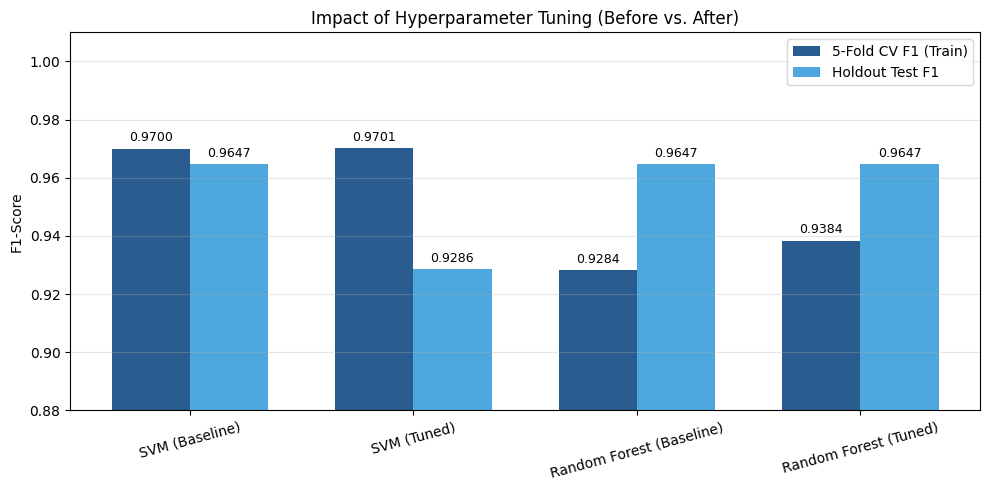

In [5]:
# 3. Before vs. After Comparison Table
comparison_df = pd.concat([baseline_df, tuned_df], ignore_index=True)

# Reorder rows to pair Baseline with Tuned
comparison_df = comparison_df.iloc[[0, 2, 1, 3]].reset_index(drop=True)

metrics_cols = ['Model', 'CV F1 (Mean)', 'CV F1 (Std)', 'Test Accuracy', 'Test Precision', 'Test Recall', 'Test F1']
print("Before vs. After Tuning Comparison:")
print(comparison_df[metrics_cols].round(4).to_string(index=False))

# Visual Comparison of CV F1 vs Test F1
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(comparison_df))
width = 0.35

rects1 = ax.bar(x - width/2, comparison_df['CV F1 (Mean)'], width, label='5-Fold CV F1 (Train)', color='#2b5c8f')
rects2 = ax.bar(x + width/2, comparison_df['Test F1'], width, label='Holdout Test F1', color='#4ea8de')

ax.set_ylabel('F1-Score')
ax.set_title('Impact of Hyperparameter Tuning (Before vs. After)')
ax.set_xticks(x)
ax.set_xticklabels(comparison_df['Model'], rotation=15)
ax.set_ylim(0.88, 1.01)
ax.legend()
ax.grid(axis='y', alpha=0.3)

for rect in rects1 + rects2:
    height = rect.get_height()
    ax.annotate(f'{height:.4f}',
                xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 3), textcoords="offset points",
                ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

## Conclusion: Was Hyperparameter Tuning Worthwhile?
* **No — Exhaustive Tuning Did Not Materially Improve Generalization:** Across `960` total model fits, `GridSearchCV` failed to outperform the default configurations on the unseen holdout test set (`n=114`).
* **Cross-Validation Overfitting in SVM:** Pushing regularization from $C=1$ to $C=50$ yielded a trivial `+0.01%` gain on training CV folds (`0.9700` $\rightarrow$ `0.9701`) at the cost of tighter decision boundaries, higher fold variance, and a **`-3.61%` drop in Test F1** (`0.9647` $\rightarrow$ `0.9286`, increasing false negatives on malignant tumors from 1 to 3). This illustrates *meta-overfitting* (overfitting the validation metric during exhaustive search on a small sample size of `455` rows).
* **Diminishing Returns in Random Forest:** While tree pruning (`min_samples_leaf=2, min_samples_split=5`) improved internal CV F1 by `+1.00%`, test-set predictions remained identical (`Test F1 = 0.9647`).
* **Final Recommendation:** Retain the simpler, lower-variance **Baseline RBF SVM (`C=1.0, gamma='scale'`)** (or **Tuned Random Forest** if tree interpretability is required), as default heuristic scaling (`gamma='scale'`) already captures the underlying feature geometry without overfitting.